# Sitting Down for the Story
## NiKo’s championship and Chinese esports fandom on Bilibili
**NMC5342 — Individual Assignment | Analytical notebook**

**Name:** Wang Xinyang · **Student ID:** A0357223H  
**Submission filename:** `NMC5342_A0357223H.ipynb` 

This notebook accompanies the report. It follows the full workflow: collection documentation,
Python fundamentals, conservative cleaning, lexical exploration, sentiment analysis, topic modelling,
and prompt-based interpretive synthesis. The author has confirmed that advanced Chinese NLP methods
and AI assistance are permitted for this assignment.

### How to run
Run cells from top to bottom. **Default review mode makes no network requests and does not download or
retrain models.** It recalculates cleaning, time windows, sentiment summaries, error checks and figures
from the supplied data. Previously fitted topic results are distinguished from fresh calculations.
Optional model-rerun cells are disabled until explicitly enabled.

**Core dependencies:** Python 3.10+, `pandas`, `numpy`, `matplotlib`, `scikit-learn`.
`wordcloud` is optional for the lexical figure. The author's original local environment is Python 3.14.8;
this notebook records the actual review environment when executed. Keep the working CUDA PyTorch build
when installing optional NLP libraries; this notebook never runs pip automatically.

**Data privacy:** this self-contained notebook embeds comment text and source identifiers for private
course review. Encoding/compression is **not anonymisation**. Keep the notebook and repository private;
do not publish it as a public GitHub artefact without reviewing data-sharing permissions and identifiers.
No cookies, session files, API keys or usernames-as-fields are included. Mentions inside original text
remain in the research data but are masked in illustrative displays.

In [ ]:
from pathlib import Path
import os, sys, io, re, json, math, hashlib, zipfile, base64, unicodedata
from collections import Counter
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

SEED = 42
THRESHOLD = 0.80
RUN_SENTIMENT_MODEL = False
RUN_TOPIC_MODEL = False
USE_LOCAL_TOPIC_ASSIGNMENTS = True
LEXICAL_TOKENIZER = "character_bigrams"  # deterministic, offline lexical check; optional "jieba"

WINDOWS_ROOT = Path(r"F:\NMC5342\NiKo_Individual_Assignment")
PROJECT_ROOT = WINDOWS_ROOT if os.name == "nt" and WINDOWS_ROOT.exists() else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "individual_report"
for folder in [OUTPUT_DIR, OUTPUT_DIR / "figures", OUTPUT_DIR / "tables", OUTPUT_DIR / "source"]:
    folder.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Tinos", "DejaVu Serif"]
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 25)

def installed_version(package):
    try: return metadata.version(package)
    except metadata.PackageNotFoundError: return "not installed"

review_environment = {"python": sys.version.split()[0], "platform": sys.platform,
    **{p: installed_version(p) for p in ["pandas","numpy","matplotlib","scikit-learn",
       "wordcloud","jieba","torch","transformers","sentence-transformers","bertopic",
       "umap-learn","hdbscan"]}}
print("Project root:", PROJECT_ROOT)
print("Outputs:", OUTPUT_DIR)
display(pd.Series(review_environment, name="review_environment"))

Project root: /mnt/data/niKo_final_work/review_run
Outputs: /mnt/data/niKo_final_work/review_run/outputs/individual_report


In [ ]:
pandas                    3.1.1
numpy                     2.5.4
matplotlib                3.11.2
scikit-learn              1.9.1
scipy                     1.18.1
wordcloud                 NOT INSTALLED
jieba                     0.42.1
torch                     2.11.0+cu128
transformers              5.22.1
sentence-transformers     6.2.0
bertopic                  0.17.4
umap-learn                0.5.12
hdbscan                   0.8.44
gensim                    NOT INSTALLED
huggingface-hub           2.4.0
tokenizers                0.23.3
accelerate                NOT INSTALLED
requests                  2.34.2
ipykernel                 NOT INSTALLED

## 1. Research question and corpus register
**RQ1:** How do sentiment and discussion patterns differ across the selected pre- and
post-championship videos?  
**RQ2:** How do commenters construct NiKo’s competitive identity and career legacy?

The three videos were purposefully selected by the researcher, not randomly sampled or independently
verified as the account's three most popular uploads. Descriptions below are concise contextual
summaries based on supplied titles/metadata and the research brief, not video-transcript analysis.
The data concern comments on these videos, not all Chinese fans or all NiKo-related discussion.

In [2]:
BVIDS = ["BV1u5GR6vELU", "BV1QSjm6wEBT", "BV1jsTi67EMC"]
SHORT_NAMES = {BVIDS[0]: "Pre-title livestream", BVIDS[1]: "Post-title thanks", BVIDS[2]: "Championship vlog"}
VIDEO_DESCRIPTIONS = {
    BVIDS[0]: "First Chinese livestream announcement; current situation and future plans.",
    BVIDS[1]: "Thank-you message to viewers following the championship.",
    BVIDS[2]: "Retrospective vlog presenting the championship experience."
}
video_register = pd.DataFrame([
    {"bvid": b, "short_name": SHORT_NAMES[b], "description": VIDEO_DESCRIPTIONS[b],
     "url": f"https://www.bilibili.com/video/{b}"} for b in BVIDS
])
display(video_register)

,bvid,short_name,description,url
0,BV1u5GR6vELU,Pre-title livestream,First Chinese livestream announcement; current situation and future plans.,https://www.bilibili.com/video/BV1u5GR6vELU
1,BV1QSjm6wEBT,Post-title thanks,Thank-you message to viewers following the championship.,https://www.bilibili.com/video/BV1QSjm6wEBT
2,BV1jsTi67EMC,Championship vlog,Retrospective vlog presenting the championship experience.,https://www.bilibili.com/video/BV1jsTi67EMC


## 2. Frozen inputs and provenance
The next collapsed cell contains a compressed copy of the supplied raw comments, completed sentiment
predictions, topic tables, original scripts and an audit manifest. It is a data snapshot, **not newly
simulated data**. SHA-256 checks protect the snapshot from silent changes.

**Topic-file availability:** the full `comments_with_topics.csv` was inspected in the preceding
conversation, but its attachment could not be reopened during final assembly. The per-video and
sentiment-by-topic counts embedded here reproduce those previously checked cross-tabs and are marked
`audited aggregate`. No comment-level topic labels have been invented. If the original file exists in
your local project, this notebook loads and checks it before using its row-level assignments; otherwise,
topic figures reproduce the recorded aggregates. This limits default-mode audit depth, not the provenance
of the reported counts. Raw and sentiment row-level data remain available in full.

The historical run's precise package versions/model revision hashes were not supplied. Model IDs and
settings are documented; a new fit need not reproduce identical cluster IDs. Review-mode arithmetic and
figures are exactly reproducible from the snapshot.

In [3]:
BUNDLE_BASE64 = '...'
archive = zipfile.ZipFile(io.BytesIO(base64.b64decode(BUNDLE_BASE64)))
BUNDLE = {name: archive.read(name) for name in archive.namelist()}
DATA_MANIFEST = json.loads(BUNDLE["manifest.json"].decode("utf-8"))
for name, entry in DATA_MANIFEST.items():
    assert hashlib.sha256(BUNDLE[name]).hexdigest() == entry["sha256"], name
print(f"Verified {len(DATA_MANIFEST)} embedded source files.")

Verified 12 embedded source files.


In [4]:
def read_bundle_csv(name):
    return pd.read_csv(io.BytesIO(BUNDLE[name]), encoding="utf-8-sig",
                       dtype={"bvid":"string", "comment_id":"string"}, keep_default_na=False)

raw = read_bundle_csv("raw_comments.csv")
sentiment_export = read_bundle_csv("sentiment_results.csv")
topic_table = read_bundle_csv("topic_table_15.csv")
rejected_topic_table = read_bundle_csv("topic_table_5_rejected.csv")
audited_topic_counts = read_bundle_csv("topic_counts_by_video_audited.csv")
audited_topic_sentiment = read_bundle_csv("topic_sentiment_audited.csv")
audited_transitions = read_bundle_csv("topic_transition_15_to_5_audited.csv")
recorded_cleaning = json.loads(BUNDLE["cleaning_summary.json"].decode("utf-8"))
assert len(raw) == 18923 and len(sentiment_export) == 18877
print("Raw rows:", len(raw), "| Completed sentiment rows:", len(sentiment_export))
display(pd.DataFrame([{"file":k, "bytes":v["bytes"], "sha256":v["sha256"]}
                      for k,v in DATA_MANIFEST.items()]))

Raw rows: 18923 | Completed sentiment rows: 18877


,file,bytes,sha256
0,raw_comments.csv,5473224,859cec2b327804d98b22cf214dfde6c332764e3948f545b39810f34f53efca25
1,sentiment_results.csv,7322156,892127e1f883786e9f473d9d34f4a4007a7e6aebe653d7f1a4f703c225cf31db
2,topic_table_15.csv,4511,a49a741a68cb2658e1cb6420fa18dce5adef5c3c039ad01f3f0fc0cbf03cd89d
3,topic_table_5_rejected.csv,1681,7a761ef046cc149e0a657fa507a9283020af69bcd6c95f3762eb68c538e4ee39
4,cleaning_summary.json,967,f7ad409993a5be32eb3719743c7b0a4b7c8c86d4c8056921cebf8fc91a25f54a
5,topic_counts_by_video_audited.csv,4324,ed7300b7dea2eb66f4e455c675a98b39130999f63e20d8a161e4409c3fd820fa
6,topic_sentiment_audited.csv,256,3536ecee5e353e1c7454a55842be197f254bb0a8af448d0753034371459bbe70
7,topic_transition_15_to_5_audited.csv,174,329f43e13af0ff2cf4f2182e90c0038a492a36b222189bff46119e5694df948f
8,source/clean_niko_comments.py,7873,9d99f3dff384dd197284d911eaf694d3efbd2219272ee01bccc64bfeb755779a
9,source/bili_niko_three_videos_sequential_v2.py,16789,4ee5a8948b9ebcf133d4739e0ac91cf2075e1df1a5426b71d04eef589d3fad5d


## 3. Python fundamentals
This small exercise demonstrates loops, a case-insensitive conditional and a reusable entity-extraction
function as requested in the guidelines. Splitting on whitespace is used **only** for the English
teaching example; it is not treated as Chinese word segmentation.

In [5]:
sentences = ["I love data.", "Python is fun!", "NUS rocks!"]
for sentence in sentences:
    print(sentence, "| words:", len(sentence.split()))
    if "python" in sentence.lower():
        print("  Contains Python (case-insensitive).")

def extract_entities(text: str) -> list[str]:
    """Return hashtags and mentions without changing the source string."""
    return re.findall(r"#\w+|@\w+", text)

assert extract_entities("I love #AI and @OpenSource!") == ["#AI", "@OpenSource"]
print(extract_entities("I love #AI and @OpenSource!"))

I love data. | words: 3
Python is fun! | words: 3
  Contains Python (case-insensitive).
NUS rocks! | words: 2
['#AI', '@OpenSource']


## 4. Collection workflow and data familiarisation
The supplied collector processed the three BVIDs sequentially using HTTP requests, video metadata,
time-ordered cursor pagination, per-video checkpoint files and CSV output. The study retained
**top-level comments only**; nested replies and bullet-screen messages were outside the scope.
Stable identifiers, rather than identical wording, were used to avoid repeated retrieval records.

The files demonstrate what was obtained; neither visible platform counts nor successful pagination
prove that deleted, moderated or inaccessible historical comments were recovered. Access permissions
are not independently established by this notebook. No live collection runs during review.

The original collector is preserved below as an inspectable source artefact. No login credentials
are included. The analysis starts from the supplied collection snapshot.

In [6]:
# Export the original code for inspectability, without executing its network entry point.
for name in ["source/bili_niko_three_videos_sequential_v2.py", "source/clean_niko_comments.py",
             "source/niko_sentiment_infer_110m_merged.py", "source/niko_bertopic_bge_pipeline_historical.py"]:
    destination = OUTPUT_DIR / "source" / Path(name).name
    destination.write_bytes(BUNDLE[name])
print("Original implementation sources preserved under", OUTPUT_DIR / "source")

display(raw.head(3).drop(columns=["comment_text"]))
raw.info()
display(raw[["like_count", "reply_count"]].describe())
quality = pd.DataFrame({"missing": raw.isna().sum(), "blank_string": raw.astype(str).eq("").sum()})
display(quality)
print("Duplicate retrieval IDs:", raw.duplicated(["bvid","comment_id"]).sum())
print("Duplicate text occurrences are retained:", raw["comment_text"].duplicated().sum())
assert raw.duplicated(["bvid","comment_id"]).sum() == 0
assert (pd.to_numeric(raw["root_id"]) == 0).all()
assert (pd.to_numeric(raw["parent_id"]) == 0).all()
print("User-level activity ranking is not calculated: no commenter username/user_id field was retained.")

Original implementation sources preserved under /mnt/data/niKo_final_work/review_run/outputs/individual_report/source


,bvid,aid,video_title,video_pubdate_sgt,comment_id,comment_timestamp,comment_date_sgt,comment_date_utc,like_count,reply_count,root_id,parent_id
0,BV1u5GR6vELU,116635172083314,【NiKo】我的中国首次直播，和大家聊聊近况与未来。,2026-05-25T20:20:50+08:00,303619745760,1779711660,2026-05-25T20:21:00+08:00,2026-05-25T12:21:00+00:00,0,0,0,0
1,BV1u5GR6vELU,116635172083314,【NiKo】我的中国首次直播，和大家聊聊近况与未来。,2026-05-25T20:20:50+08:00,300606089073,1779711666,2026-05-25T20:21:06+08:00,2026-05-25T12:21:06+00:00,0,0,0,0
2,BV1u5GR6vELU,116635172083314,【NiKo】我的中国首次直播，和大家聊聊近况与未来。,2026-05-25T20:20:50+08:00,300606090305,1779711667,2026-05-25T20:21:07+08:00,2026-05-25T12:21:07+00:00,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18923 entries, 0 to 18922
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   bvid               18923 non-null  string
 1   aid                18923 non-null  int64 
 2   video_title        18923 non-null  object
 3   video_pubdate_sgt  18923 non-null  object
 4   comment_id         18923 non-null  string
 5   comment_timestamp  18923 non-null  int64 
 6   comment_date_sgt   18923 non-null  object
 7   comment_date_utc   18923 non-null  object
 8   comment_text       18923 non-null  object
 9   like_count         18923 non-null  int64 
 10  reply_count        18923 non-null  int64 
 11  root_id            18923 non-null  int64 
 12  parent_id          18923 non-null  int64 
dtypes: int64(6), object(5), string(2)
memory usage: 1.9+ MB


,like_count,reply_count
count,18923.000000,18923.000000
mean,28.287217,1.496433
std,471.340908,50.489783
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,0.000000
max,27418.000000,6197.000000


,missing,blank_string
bvid,0,0
aid,0,0
video_title,0,0
video_pubdate_sgt,0,0
comment_id,0,0
comment_timestamp,0,0
comment_date_sgt,0,0
comment_date_utc,0,0
comment_text,0,0
like_count,0,0


Duplicate retrieval IDs: 0
Duplicate text occurrences are retained: 3314
User-level activity ranking is not calculated: no commenter username/user_id field was retained.


### Initial observations
The collection contains 18,923 top-level comments spread unevenly across three videos. Text and timestamp
fields are retained, but no user-level identifier suitable for ranking active commenters is available.
Identical expressions occur repeatedly and may reflect community participation, so text duplication is
not equated with duplicate retrieval. Later comments also appear beneath older videos. Cleaning therefore
separates irrelevant solicitation from culturally meaningful short or repetitive responses, and temporal
analysis uses comment time rather than the video's label alone.

## 5. Conservative cleaning, with an audit trail
Only purely numerical comments and clear solicitation/promotional comments are removed. Ambiguous
promotional candidates remain in the data. Emoji, punctuation, slang, links in ordinary fan contributions,
short comments and repeated wording are preserved. The code below is the original implemented cleaning
rule set, not a newly broadened filter.

In [7]:
PURE_NUMBER = re.compile(r"\d+(?:\s+\d+)*\Z", flags=re.UNICODE)

DIRECT_MARKETING = [
    ("referral_link", re.compile(r"https?://[^\s]*?(?:invite_token|referral_code|affiliate_id|lottery_id)\s*=", re.I)),
    ("contact_sales", re.compile(r"(?:会员|福利|付费|特惠|折扣|优惠|低价|资源|教程|代练|代打).{0,18}(?:加\s*[vV]|加\s*(?:vx|VX|微(?:信)?|Q[Qq]?|扣扣)|扫码|私信购买|私聊购买|进群)", re.I | re.S)),
    ("contact_sales", re.compile(r"(?:加\s*[vV]|加\s*(?:vx|VX|微(?:信)?|Q[Qq]?|扣扣)|扫码进群|私信购买|私聊购买).{0,18}(?:会员|福利|付费|特惠|折扣|优惠|低价|代练|代打)", re.I | re.S)),
    ("off_topic_clickbait", re.compile(r"(?:想看|要看|来看|领取|免费领).{0,12}(?:福利|资源|照片|视频).{0,10}(?:点我头像|看我头像|点我主页|看我主页|戳我头像|扫码|私信我)", re.I | re.S)),
    ("self_promotion", re.compile(r"(?:锁定我的直播间|来我的直播间|来看我的直播|来我直播间|我的直播间见|去我直播间看)", re.I)),
    ("follow_exchange", re.compile(r"(?:诚信互关|互关互粉|互粉互赞|关注我(?:可以|就能)?互粉|互粉不要取关|互关不取关)", re.I)),
    # 明确的商品兜售。只匹配 *出售/售卖/现货+实体商品词*，不匹配粉丝的「想买」「已下单」。
    ("direct_selling", re.compile(r"^\s*(?:出售|售卖|现货出售|低价出售|低价出|接单代购)\s*(?:NiKo|Niko|niko|老尼|尼公子|猎鹰|Falcons|法尔孔|战队)?\s*(?:周边|队服|鼠标|耳机|键盘|手办|账号|皮肤|游戏币)\b", re.I)),
]

REVIEW_MARKERS = [
    ("possible_promotion_or_giveaway", re.compile(r"免费领|免费送|领取福利|出售|售卖|私信转账|加[vV]|互关|互粉|扫码|推广码|邀请码|invite_token|点我头像|看我头像|点我主页|点链接|求关注|马上关注我|抽奖链接|点击领取", re.I)),
]

def judge_comment(raw_text: str) -> tuple[str, str]:
    """返回 (keep|remove|review, reason)。review 行仍进入清洗后的文件。"""
    # 匹配前可统一全角字符/空格；原文本不作任何修改。
    check = unicodedata.normalize("NFKC", raw_text).strip()
    if PURE_NUMBER.fullmatch(check):
        return "remove", "pure_number"
    for reason, pattern in DIRECT_MARKETING:
        if pattern.search(check):
            return "remove", reason
    for reason, pattern in REVIEW_MARKERS:
        if pattern.search(check):
            return "review", reason
    return "keep", ""

In [8]:
cleaning_decisions = raw["comment_text"].map(judge_comment)
cleaning_status = cleaning_decisions.map(lambda x: x[0])
cleaning_reason = cleaning_decisions.map(lambda x: x[1])
cleaned = raw.loc[cleaning_status.ne("remove")].copy()
removed = raw.loc[cleaning_status.eq("remove")].copy()
removed["removal_reason"] = cleaning_reason.loc[removed.index]
assert len(cleaned) == 18877 and len(removed) == 46
assert cleaned["comment_id"].tolist() == sentiment_export["comment_id"].tolist()
assert cleaned["comment_text"].tolist() == sentiment_export["comment_text"].tolist()
assert removed["removal_reason"].eq("pure_number").sum() == 39
assert cleaning_status.eq("review").sum() == 6
cleaning_by_video = pd.DataFrame({"raw":raw.groupby("bvid").size(),
                                  "retained":cleaned.groupby("bvid").size()}).reindex(BVIDS)
cleaning_by_video["removed"] = cleaning_by_video["raw"] - cleaning_by_video["retained"]
display(cleaning_by_video)
display(removed["removal_reason"].value_counts().rename("removed_count"))
cleaning_by_video.to_csv(OUTPUT_DIR / "tables" / "cleaning_by_video.csv",encoding="utf-8-sig")

,raw,retained,removed
bvid,,,
BV1u5GR6vELU,3662,3652,10
BV1QSjm6wEBT,10249,10230,19
BV1jsTi67EMC,5012,4995,17


removal_reason
pure_number            39
referral_link           2
contact_sales           1
self_promotion          1
off_topic_clickbait     1
follow_exchange         1
direct_selling          1
Name: removed_count, dtype: int64

## 6. Time windows and sampling units
Dates are read from the exported metadata, standardised in UTC, and displayed as Singapore time (UTC+8).
A seven-day sample is the half-open interval **[publication, publication + 168 hours)**. Fourteen days and
the complete collected corpus are sensitivity views, not alternative results selected to improve the
story. Counts refer to comments, while the study has only **three video contexts**. No significance test
here treats thousands of comments as independent replications of a championship effect.

In [9]:
df = sentiment_export.copy()
df["post_time_utc"] = pd.to_datetime(df["video_pubdate_sgt"], errors="coerce", utc=True)
df["comment_time_utc"] = pd.to_datetime(df["comment_date_sgt"], errors="coerce", utc=True)
assert df[["post_time_utc","comment_time_utc"]].notna().all().all()
assert df["comment_time_utc"].eq(pd.to_datetime(pd.to_numeric(df["comment_timestamp"]), unit="s", utc=True)).all()
df["age_hours"] = (df["comment_time_utc"] - df["post_time_utc"]).dt.total_seconds() / 3600
assert df["age_hours"].ge(0).all()
df["within_7d"] = df["age_hours"].ge(0) & df["age_hours"].lt(168)
df["within_14d"] = df["age_hours"].ge(0) & df["age_hours"].lt(336)
video_stats = df.groupby("bvid", sort=False).agg(
    title=("video_title","first"), published=("video_pubdate_sgt","first"),
    all_comments=("comment_id","size"), first_7d=("within_7d","sum"), first_14d=("within_14d","sum"),
    earliest_comment=("comment_date_sgt","min"), latest_comment=("comment_date_sgt","max"))
video_stats["description"] = pd.Series(VIDEO_DESCRIPTIONS)
display(video_stats)
assert int(df["within_7d"].sum()) == 17319
late_cutoff = pd.Timestamp("2026-06-22", tz="Asia/Singapore").tz_convert("UTC")
late_pre = df["bvid"].eq(BVIDS[0]) & df["comment_time_utc"].ge(late_cutoff)
print("Comments on the pre-title video posted on/after 22 June:", int(late_pre.sum()))
assert int(late_pre.sum()) == 856
video_stats.to_csv(OUTPUT_DIR / "tables" / "video_register.csv", encoding="utf-8-sig")

,title,published,all_comments,first_7d,first_14d,earliest_comment,latest_comment,description
bvid,,,,,,,,
BV1u5GR6vELU,【NiKo】我的中国首次直播，和大家聊聊近况与未来。,2026-05-25T20:20:50+08:00,3652,2723,2735,2026-05-25T20:21:00+08:00,2026-09-13T00:44:58+08:00,First Chinese livestream announcement; current situation and future plans.
BV1QSjm6wEBT,【NiKo】谢谢你们❤️,2026-06-24T00:20:42+08:00,10230,9914,10048,2026-06-24T00:20:55+08:00,2026-11-02T02:21:02+08:00,Thank-you message to viewers following the championship.
BV1jsTi67EMC,【vlog】我们是冠军🏆,2026-07-01T23:44:16+08:00,4995,4682,4764,2026-07-01T23:44:25+08:00,2026-10-31T15:16:09+08:00,Retrospective vlog presenting the championship experience.


Comments on the pre-title video posted on/after 22 June: 856


## 7. Lexical exploration: a separate, transparent view
This descriptive check is **not a replacement** for BGE embeddings or the historical BERTopic tokenizer.
The offline default counts Chinese character bigrams plus complete Latin terms, after removing platform
emoji codes and mentions in a **derived** lexical string. It avoids requiring a network installation to
review the notebook. Overlapping bigrams are lexical patterns, not linguistically validated words.

Set `LEXICAL_TOKENIZER="jieba"` to use locally installed Jieba with the domain dictionary; the output records
which tokenizer was used. Chinese does not require mechanically applying English stemming/lemmatisation.
Original comments remain unchanged for sentiment, quotations and interpretation. Frequency counts and
TF-IDF are descriptive checks; they do not establish five narrative categories.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
DOMAIN_TERMS = ["NiKo","niko","老尼","尼神","老霸","老爸","无冕之王","圆梦","梦碎",
                "科隆Major","科隆","Major","Falcons","大表哥","karrigan","GOAT",
                "定制冠军","软脚虾","我坐好了","坐好了","老霸道了","冠军"]
LEXICAL_STOP = {"我们","你们","他们","这个","那个","真的","什么","怎么","就是","已经",
                "一个","可以","没有","还有","不是","时候","一下","the","and","you","your",
                "this","that","for","are","with","from","have","not","but"}
if LEXICAL_TOKENIZER == "jieba":
    import jieba
    for term in DOMAIN_TERMS: jieba.add_word(term)

def lexical_tokens(text: str) -> list[str]:
    derived = re.sub(r"https?://\S+", " ", str(text))
    derived = re.sub(r"\[[^\[\]\r\n]{1,40}\]", " ", derived)
    derived = re.sub(r"[@＠][^\s@＠\[\],，:：;；]+", " ", derived)
    if LEXICAL_TOKENIZER == "jieba":
        candidates = [w.strip().casefold() for w in jieba.lcut(derived)]
        return [w for w in candidates if len(w) >= 2 and
                re.search(r"[\u4e00-\u9fffA-Za-z]",w) and w not in LEXICAL_STOP]
    candidates = re.findall(r"[A-Za-z][A-Za-z0-9'-]*", derived.casefold())
    for sequence in re.findall(r"[\u4e00-\u9fff]+", derived):
        candidates.extend(sequence[i:i+2] for i in range(len(sequence)-1))
    return [w for w in candidates if len(w) >= 2 and w not in LEXICAL_STOP]

lexical_documents = df["comment_text"].map(lexical_tokens)
term_counts = Counter(token for tokens in lexical_documents for token in tokens)
frequency_table = pd.DataFrame(term_counts.most_common(60), columns=["term","frequency"])
print("Lexical tokenizer:", LEXICAL_TOKENIZER)
display(frequency_table.head(20))
vectorizer = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=5)
X = vectorizer.fit_transform(lexical_documents.map(" ".join))
features = vectorizer.get_feature_names_out()
mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
tfidf_table = pd.DataFrame({"term":features, "mean_tfidf":mean_tfidf}).sort_values("mean_tfidf",ascending=False)
display(tfidf_table.head(20))
frequency_table.to_csv(OUTPUT_DIR/"tables"/"lexical_frequencies.csv",index=False,encoding="utf-8-sig")
tfidf_table.head(200).to_csv(OUTPUT_DIR/"tables"/"lexical_tfidf.csv",index=False,encoding="utf-8-sig")

Lexical tokenizer: character_bigrams


,term,frequency
0,niko,4564
1,major,3446
2,冠军,1783
3,坐好,1779
4,科隆,1650
5,决赛,1525
6,老尼,1245
7,好了,1231
8,vlog,1225
9,无数,1140


,term,mean_tfidf
272,niko,0.028391
3598,坐好,0.024189
3915,好了,0.023172
5178,我坐,0.019286
8312,老霸,0.018525
9925,霸道,0.017831
9532,道了,0.017610
238,major,0.014739
5188,我已,0.014353
8302,老尼,0.014146


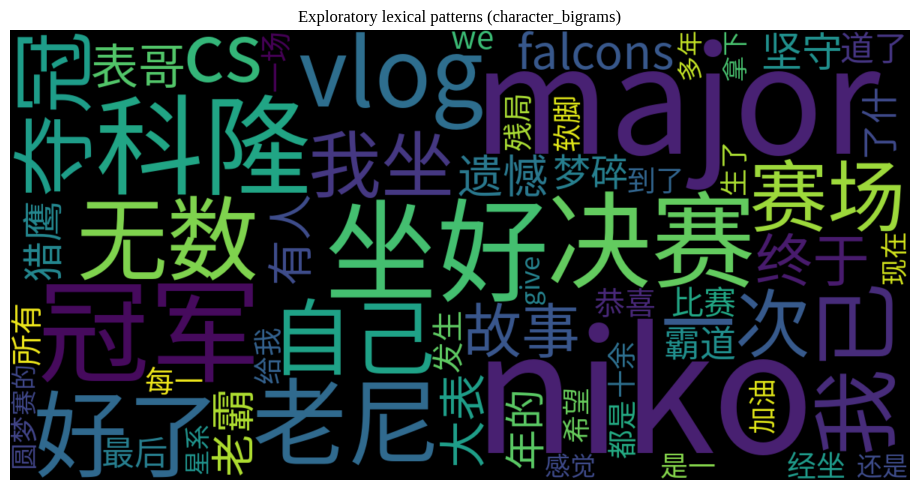

In [11]:
# Optional word cloud: a lexical description, not a topic-model visualisation.
try:
    from wordcloud import WordCloud
    font_candidates = [Path(r"C:\Windows\Fonts\msyh.ttc"), Path(r"C:\Windows\Fonts\simsun.ttc"),
        Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
        Path("/usr/share/fonts/opentype/noto/NotoSerifCJK-Regular.ttc")]
    cjk_font = next((str(p) for p in font_candidates if p.exists()), None)
    if cjk_font:
        cloud = WordCloud(font_path=cjk_font, width=1200, height=600, max_words=60,
                          random_state=SEED, collocations=False).generate_from_frequencies(dict(term_counts))
        fig, ax = plt.subplots(figsize=(10,5))
        ax.imshow(cloud, interpolation="bilinear"); ax.axis("off")
        ax.set_title(f"Exploratory lexical patterns ({LEXICAL_TOKENIZER})")
        fig.tight_layout(); fig.savefig(OUTPUT_DIR/"figures"/"lexical_wordcloud.png",dpi=180)
        plt.show(); plt.close(fig)
    else:
        print("Word cloud skipped: configure a local Chinese font; no font files are bundled.")
except ImportError:
    print("Word cloud skipped: optional wordcloud package is not installed. Frequency/TF-IDF tables are complete.")

## 8. Sentiment model: completed predictions and optional re-inference
The supplied model is `IDEA-CCNL/Erlangshen-Roberta-110M-Sentiment`, a Chinese binary classifier.
The existing script used a 512-token maximum. Review mode does not refit or relabel the data.
Scores are softmax outputs, **not calibrated probabilities of correctness**.

Optional code below shows the actual inference operations. `RUN_SENTIMENT_MODEL=False` leaves the
completed export unchanged. A fresh run saves a separate file rather than silently replacing the
historical results. Model revision was not recorded in the original export; pin it when creating a new run.

In [12]:
def rerun_sentiment(texts, batch_size=32, model_id="IDEA-CCNL/Erlangshen-Roberta-110M-Sentiment", revision=None):
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    torch.manual_seed(SEED)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(model_id, revision=revision)
    model = AutoModelForSequenceClassification.from_pretrained(model_id, revision=revision).to(device).eval()
    labels = {int(k): str(v).casefold() for k,v in model.config.id2label.items()}
    print("Checkpoint labels:", labels)
    neg = next((k for k,v in labels.items() if "negative" in v or v == "负面"), None)
    pos = next((k for k,v in labels.items() if "positive" in v or v == "正面"), None)
    if neg is None or pos is None:
        raise ValueError("Cannot verify label mapping; inspect model config rather than guessing.")
    result=[]
    with torch.inference_mode():
        for start in range(0,len(texts),batch_size):
            encoded=tokenizer(list(texts[start:start+batch_size]), padding=True, truncation=True,
                              max_length=512, return_tensors="pt")
            encoded={k:v.to(device) for k,v in encoded.items()}
            probability=torch.softmax(model(**encoded).logits.float(),dim=-1).cpu().numpy()
            result.extend({"positive_prob":float(p[pos]),"negative_prob":float(p[neg])} for p in probability)
    return pd.DataFrame(result)

if RUN_SENTIMENT_MODEL:
    fresh_scores = rerun_sentiment(df["comment_text"].astype(str).tolist())
    fresh_output = pd.concat([df[["bvid","comment_id"]].reset_index(drop=True),fresh_scores],axis=1)
    fresh_output.to_csv(OUTPUT_DIR/"tables"/"sentiment_rerun_SEPARATE.csv",index=False,encoding="utf-8-sig")
else:
    print("Using supplied completed sentiment predictions; no model inference executed in review mode.")

Using supplied completed sentiment predictions; no model inference executed in review mode.


In [13]:
for col in ["positive_prob", "negative_prob", "max_prob"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
assert df[["positive_prob","negative_prob"]].ge(0).all().all()
assert df[["positive_prob","negative_prob"]].le(1).all().all()
assert np.allclose(df["positive_prob"]+df["negative_prob"],1,atol=1e-6)
assert np.allclose(df["max_prob"],df[["positive_prob","negative_prob"]].max(axis=1),atol=1e-6)
SENTIMENT_ORDER=["Positive (≥0.80)", "Uncertain (<0.80)", "Negative (≥0.80)"]
df["sentiment_report"] = np.select([df["positive_prob"].ge(THRESHOLD),df["negative_prob"].ge(THRESHOLD)],
        [SENTIMENT_ORDER[0],SENTIMENT_ORDER[2]],default=SENTIMENT_ORDER[1])

def sentiment_summary(frame):
    counts=pd.crosstab(frame["bvid"],frame["sentiment_report"]).reindex(index=BVIDS,columns=SENTIMENT_ORDER,fill_value=0)
    counts["total"]=counts.sum(axis=1)
    percentages=counts[SENTIMENT_ORDER].div(counts["total"],axis=0).mul(100)
    return counts,percentages

all_counts,all_pct=sentiment_summary(df)
seven_counts,seven_pct=sentiment_summary(df[df["within_7d"]])
fourteen_counts,fourteen_pct=sentiment_summary(df[df["within_14d"]])
for label,counts,pct in [("all",all_counts,all_pct),("7d",seven_counts,seven_pct),("14d",fourteen_counts,fourteen_pct)]:
    print("Window:",label)
    display(counts.join(pct.add_suffix(" %")).round(2))
    counts.join(pct.add_suffix("_pct")).to_csv(OUTPUT_DIR/"tables"/f"sentiment_{label}.csv",encoding="utf-8-sig")
assert all_counts[SENTIMENT_ORDER].sum().tolist()==[9826,5906,3145]
assert seven_counts[SENTIMENT_ORDER].sum().tolist()==[9011,5452,2856]
print("Uncertain is NOT the classifier's neutral label.")

Window: all


sentiment_report,Positive (≥0.80),Uncertain (<0.80),Negative (≥0.80),total,Positive (≥0.80) %,Uncertain (<0.80) %,Negative (≥0.80) %
bvid,,,,,,,
BV1u5GR6vELU,1746,1245,661,3652,47.81,34.09,18.10
BV1QSjm6wEBT,5520,3090,1620,10230,53.96,30.21,15.84
BV1jsTi67EMC,2560,1571,864,4995,51.25,31.45,17.30


Window: 7d


sentiment_report,Positive (≥0.80),Uncertain (<0.80),Negative (≥0.80),total,Positive (≥0.80) %,Uncertain (<0.80) %,Negative (≥0.80) %
bvid,,,,,,,
BV1u5GR6vELU,1249,987,487,2723,45.87,36.25,17.88
BV1QSjm6wEBT,5361,2989,1564,9914,54.08,30.15,15.78
BV1jsTi67EMC,2401,1476,805,4682,51.28,31.52,17.19


Window: 14d


sentiment_report,Positive (≥0.80),Uncertain (<0.80),Negative (≥0.80),total,Positive (≥0.80) %,Uncertain (<0.80) %,Negative (≥0.80) %
bvid,,,,,,,
BV1u5GR6vELU,1256,991,488,2735,45.92,36.23,17.84
BV1QSjm6wEBT,5440,3023,1585,10048,54.14,30.09,15.77
BV1jsTi67EMC,2449,1503,812,4764,51.41,31.55,17.04


Uncertain is NOT the classifier's neutral label.


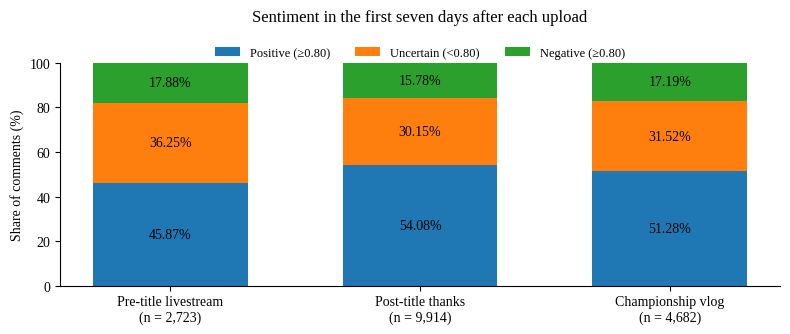

In [14]:
def sentiment_figure(percentages, counts, path=None):
    fig,ax=plt.subplots(figsize=(8.0,3.45))
    x=np.arange(len(BVIDS)); bottom=np.zeros(len(BVIDS))
    for category,hatch in zip(SENTIMENT_ORDER,["", "", ""]):
        values=percentages[category].to_numpy()
        ax.bar(x,values,bottom=bottom,label=category,width=.62,hatch=hatch)
        for i,value in enumerate(values):
            ax.text(i,bottom[i]+value/2,f"{value:.2f}%",ha="center",va="center",fontsize=10)
        bottom+=values
    ax.set_xticks(x,[SHORT_NAMES[b]+f"\n(n = {int(counts.loc[b,'total']):,})" for b in BVIDS])
    ax.set_ylim(0,100); ax.set_ylabel("Share of comments (%)")
    ax.set_title("Sentiment in the first seven days after each upload",pad=30)
    ax.legend(loc="upper center",bbox_to_anchor=(.5,1.12),ncol=3,frameon=False,fontsize=9)
    ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout()
    if path: fig.savefig(path,dpi=240,bbox_inches="tight")
    return fig

fig=sentiment_figure(seven_pct,seven_counts,OUTPUT_DIR/"figures"/"figure1_sentiment_7d.png")
plt.show();plt.close(fig)

### Reading the sentiment comparison
Within equal seven-day windows, the two post-title videos have larger shares of high-confidence positive
labels than the livestream announcement. The comparison is descriptive. The videos differ in genre,
invitation to participate, exposure and audience composition. It does not establish that winning caused
an attitude shift. Fourteen-day and full-corpus summaries are retained above for transparency.

In [15]:
threshold_sensitivity=[]
for threshold in [.60,.70,.80,.90]:
    for bvid,grp in df[df["within_7d"]].groupby("bvid",sort=False):
        p=grp["positive_prob"].ge(threshold).sum(); n=grp["negative_prob"].ge(threshold).sum()
        threshold_sensitivity.append({"bvid":bvid,"threshold":threshold,"positive_pct":100*p/len(grp),
            "negative_pct":100*n/len(grp),"uncertain_pct":100*(len(grp)-p-n)/len(grp)})
display(pd.DataFrame(threshold_sensitivity).round(2))

bracket_only=df["comment_text"].str.fullmatch(r"\s*(?:\[[^\[\]\r\n]{1,40}\]\s*)+",na=False)
bracket_counts=df.loc[bracket_only,"sentiment_report"].value_counts().reindex(SENTIMENT_ORDER,fill_value=0)
assert int(bracket_only.sum())==846
assert int(bracket_counts[SENTIMENT_ORDER[2]])==390
display(bracket_counts.rename("bracket_only_comments"))
print("Model-high-negative share among bracket-only expressions:",round(100*390/846,2),"%")

# These are evidence examples, not an independently coded accuracy benchmark.
def mask_mentions(text):
    return re.sub(r"[@＠][^\s@＠\[\],，:：;；]+", "@user", str(text))

example_queries=["[打call][打call]", "goat rifler[打call]", "男人一生只哭19次", "我已经0.000001秒没听过niko夺冠了的故事了"]
example_rows=[]
for phrase in example_queries:
    found=df[df["comment_text"].str.contains(phrase,case=False,regex=False)]
    if not found.empty:
        r=found.iloc[0]
        example_rows.append({"text":mask_mentions(r["comment_text"])[:450],"bvid":r["bvid"],
                             "negative_score":r["negative_prob"],"label":r["sentiment_report"]})
display(pd.DataFrame(example_rows))

,bvid,threshold,positive_pct,negative_pct,uncertain_pct
0,BV1u5GR6vELU,0.6,60.82,28.87,10.32
1,BV1QSjm6wEBT,0.6,66.57,25.48,7.95
2,BV1jsTi67EMC,0.6,65.91,26.42,7.67
3,BV1u5GR6vELU,0.7,54.79,23.65,21.56
4,BV1QSjm6wEBT,0.7,60.04,19.41,20.56
5,BV1jsTi67EMC,0.7,57.86,21.23,20.91
6,BV1u5GR6vELU,0.8,45.87,17.88,36.25
7,BV1QSjm6wEBT,0.8,54.08,15.78,30.15
8,BV1jsTi67EMC,0.8,51.28,17.19,31.52
9,BV1u5GR6vELU,0.9,33.79,13.48,52.74


sentiment_report
Positive (≥0.80)     110
Uncertain (<0.80)    346
Negative (≥0.80)     390
Name: bracket_only_comments, dtype: int64

Model-high-negative share among bracket-only expressions: 46.1 %


,text,bvid,negative_score,label
0,[打call][打call],BV1u5GR6vELU,0.995808,Negative (≥0.80)
1,goat rifler[打call],BV1QSjm6wEBT,0.996858,Negative (≥0.80)
2,男人一生只哭19次：\nNiKo梦碎2015克卢日纳波卡Major😭\nNiKo梦碎2016哥伦布Major😭\nNiKo梦碎2017科隆Major😭\nNiKo梦碎2017亚特兰大Major...,BV1u5GR6vELU,0.995029,Negative (≥0.80)
3,我已经0.000001秒没听过niko夺冠了的故事了[星星眼],BV1u5GR6vELU,0.888093,Negative (≥0.80)


**Interpretation, not validation accuracy.** Cheering emoji, English praise and humorous negation can
receive negative labels. Some crying expressions are ambiguous; not every negative-labelled emoji is
necessarily an error. Long recollections of defeat may also end in celebration. Sentiment, emotional
arousal and stance toward NiKo are distinct constructs. No independently annotated gold standard or
controlled BERT–LLM classification comparison was completed, so no accuracy, Macro-F1 or claim of LLM
superiority is reported.

## 9. BERTopic: historical model settings and optional rerun
The historical workflow embedded distinct derived texts with `BAAI/bge-base-zh-v1.5`, normalised the
vectors, reduced them with UMAP and clustered with HDBSCAN. Jieba was used only for c-TF-IDF, not to
replace original sentences before BGE encoding. Texts longer than 450 characters used a documented
head–tail representation (225 characters at each end); full original text remained available for reading.

Parameters: seed 42; UMAP neighbours 20, components 5, `min_dist=0`, cosine metric;
HDBSCAN `min_cluster_size=100`, `min_samples=10`, Euclidean metric, EOM selection.
The recorded run yielded **38 non-outlier clusters**, reduced to **15** for interpretation.
`-1` remains an unassigned group. The numerical five-topic reduction is retained only as a rejected
exploratory diagnostic, never substituted for the five interpretive themes.

In [16]:
def normalize_embedding_input(text, max_chars=450):
    normalized=re.sub(r"\s+"," ",str(text)).strip()
    if len(normalized)>max_chars:
        return normalized[:max_chars//2]+" …… "+normalized[-(max_chars-max_chars//2):]
    return normalized

df["embedding_input"]=df["comment_text"].map(normalize_embedding_input)
unique_docs=pd.unique(df["embedding_input"]).tolist()
print("Full comments:",len(df),"| distinct derived texts:",len(unique_docs))
print("Repeated raw text occurrences:",df["comment_text"].duplicated().sum())
print("Texts longer than 450 characters:",df["comment_text"].str.len().gt(450).sum())
assert len(unique_docs)==15566
assert int(df["comment_text"].duplicated().sum())==3287

Full comments: 18877 | distinct derived texts: 15566
Repeated raw text occurrences: 3287
Texts longer than 450 characters: 367


In [17]:
EMOJI_TOKEN = re.compile(r'(\[[^\[\]\r\n]{1,40}\])')

PUNCT_ONLY = re.compile(r'^[\W_]+$', flags=re.UNICODE)

UNINFORMATIVE_WORDS = {
    '的','了','呢','吗','啊','呀','吧','嘛','哦','是','在','和','与','或','个','这','那',
    '我','你','他','她','它','我们','你们','他们','自己','一个','一些','那个',
    '这个','就是','还有','但是','因为','所以','如果','然后','已经','可以','真的','还是',
    '一下','一样','什么','怎么','为什么','多少','不是','没有','这样','那样','时候',
    '有点','现在','感觉','可能','非常','比较','之后','之前','今天','明天','昨天',
    'the','and','that','with','you','your','have','for','this','was','are','from',
    'www','http','https','com','bilibili',
}

DOMAIN_TERMS = [
    'NiKo','NIKO','niko','老尼','尼神','老霸','老爸','尼古拉','尼古拉科维奇',
    '无冕之王','圆梦','梦碎','科隆Major','科隆','Major','major','猎鹰',
    'Falcons','大表哥','karrigan','Karrigan','GOAT','步枪GOAT',
    '定制冠军','软脚虾','十年饮冰','我坐好了','坐好了','真拿你没办法',
    'ZywOo','donk','FURIA','蒙古','大满贯',
]

def zh_tokenize(text: str) -> list[str]:
    """c-TF-IDF tokenizer; NOT used to tokenize BGE embedding input."""
    import jieba
    tokens = []
    for segment in EMOJI_TOKEN.split(str(text)):
        if not segment:
            continue
        parts = [segment] if segment.startswith('[') and segment.endswith(']') else jieba.lcut(segment)
        for word in parts:
            word = str(word).strip()
            if not word or word.casefold() in UNINFORMATIVE_WORDS:
                continue
            if PUNCT_ONLY.fullmatch(word):
                continue
            # Keep Chinese one-character words and all Bilibili bracket emojis.
            tokens.append(word)
    return tokens

def configure_jieba() -> None:
    import jieba
    for term in DOMAIN_TERMS:
        jieba.add_word(term)

In [18]:
def refit_topics(docs, full_frame, batch_size=32):
    """Optional refit; original settings, no forced 15-to-5 reduction."""
    import torch
    from sentence_transformers import SentenceTransformer
    from bertopic import BERTopic
    from umap import UMAP
    from hdbscan import HDBSCAN
    from sklearn.feature_extraction.text import CountVectorizer
    device="cuda" if torch.cuda.is_available() else "cpu"
    encoder=SentenceTransformer("BAAI/bge-base-zh-v1.5",device=device)
    encoder.max_seq_length=512
    embeddings=encoder.encode(docs,batch_size=batch_size,normalize_embeddings=True,
                              convert_to_numpy=True,show_progress_bar=True)
    configure_jieba()
    vectorizer=CountVectorizer(tokenizer=zh_tokenize,token_pattern=None,lowercase=False,
                              min_df=1,max_df=.95,ngram_range=(1,1))
    model=BERTopic(embedding_model=None,
        umap_model=UMAP(n_neighbors=20,n_components=5,min_dist=0.0,metric="cosine",random_state=42,low_memory=True),
        hdbscan_model=HDBSCAN(min_cluster_size=100,min_samples=10,metric="euclidean",
                             cluster_selection_method="eom",prediction_data=False),
        vectorizer_model=vectorizer,top_n_words=10,calculate_probabilities=False,verbose=True,nr_topics=None)
    initial,_=model.fit_transform(docs,embeddings=embeddings)
    raw_topics=np.asarray(initial).copy()
    topic_count=len(set(initial)-{-1})
    if topic_count>15:
        model.reduce_topics(docs,nr_topics=15+int(-1 in initial))
    final_topics=np.asarray(model.topics_)
    rerun_frame=full_frame.copy()
    rerun_frame["topic_raw_rerun"]=rerun_frame["embedding_input"].map(dict(zip(docs,raw_topics)))
    rerun_frame["topic_15_rerun"]=rerun_frame["embedding_input"].map(dict(zip(docs,final_topics)))
    model.get_topic_info().to_csv(OUTPUT_DIR/"tables"/"topic_info_rerun_SEPARATE.csv",index=False,encoding="utf-8-sig")
    rerun_frame.to_csv(OUTPUT_DIR/"tables"/"comments_topics_rerun_SEPARATE.csv",index=False,encoding="utf-8-sig")
    print("Fresh run topic counts:",topic_count,"->",len(set(final_topics)-{-1}))
    print("Do not reuse historical topic interpretations without re-reading the new clusters.")
    return model

if RUN_TOPIC_MODEL:
    new_topic_model=refit_topics(unique_docs,df)
else:
    print("Using supplied historical topic results; BGE/BERTopic fitting was not rerun in review mode.")

Using supplied historical topic results; BGE/BERTopic fitting was not rerun in review mode.


## 10. Topic assignments, cross-tabs and the rejected five-cluster reduction
Default output uses the previously verified aggregate export when the full assignment file is absent.
A local matching assignment file enables fresh row-level cross-tabs; it must agree with the corpus IDs
and with the historical counts. A different clustering run is not silently substituted.

In [19]:
assignment_candidates=[PROJECT_ROOT/"outputs"/"bertopic_niko"/"comments_with_topics.csv",
                       PROJECT_ROOT/"data"/"processed"/"comments_with_topics.csv",
                       PROJECT_ROOT/"comments_with_topics.csv"]
assignment_path=next((p for p in assignment_candidates if p.exists()),None)
topics_rows=None
if USE_LOCAL_TOPIC_ASSIGNMENTS and assignment_path is not None:
    candidate=pd.read_csv(assignment_path,encoding="utf-8-sig",dtype={"bvid":"string","comment_id":"string"})
    assert not candidate.duplicated(["bvid","comment_id"]).any()
    assert len(candidate)==len(df)
    topics_rows=df.merge(candidate[["bvid","comment_id","topic_raw","topic_15","topic_5"]],
                         on=["bvid","comment_id"],how="left",validate="one_to_one")
    assert topics_rows["topic_15"].notna().all()
    topic_counts=topics_rows.groupby(["topic_15","bvid"]).size().reset_index(name="comment_count")
    actual=topic_counts.pivot(index="topic_15",columns="bvid",values="comment_count").fillna(0).astype(int)
    expected=audited_topic_counts.pivot(index="topic_15",columns="bvid",values="comment_count").fillna(0).astype(int)
    pd.testing.assert_frame_equal(actual.sort_index().reindex(columns=BVIDS),
                                  expected.sort_index().reindex(columns=BVIDS),check_dtype=False)
    topic_data_source="Recomputed from local comment-level assignments (matched historical run)"
else:
    topic_counts=audited_topic_counts[["topic_15","bvid","comment_count"]].copy()
    topic_data_source="Previously verified aggregate audit; row-level topic file unavailable in embedded snapshot"

print(topic_data_source)
by_topic=topic_counts.groupby("topic_15")["comment_count"].sum().sort_index()
expected_totals=topic_table.set_index("topic_id")["full_comment_count"].sort_index()
pd.testing.assert_series_equal(by_topic,expected_totals,check_names=False,check_dtype=False)
assert int(topic_counts["comment_count"].sum())==len(df)
print("Unassigned -1:",int(by_topic.loc[-1]),"=",round(100*by_topic.loc[-1]/len(df),2),"%")
print("Historical raw clusters: 38 (recorded in prior assignment audit; source model not re-fitted here).")

topic_labels={
 0:"Championship, performance and legacy (mixed)",1:"Emoji and mention-heavy interaction (mixed)",
 2:"Vlog/livestream engagement and production",3:"Taking a seat / inviting the story",
 4:"English slogans, belief and achievement",5:"Perseverance, redemption and poetic reflection",
 6:"Support, praise and identification (mixed)",7:"Affectionate NiKo-addressed discussion (mixed)",
 8:"How long since hearing the story / other mixed queries",9:"Livestream surprise and anticipation",
 10:"Kinship-style fan address",11:"Falcons/team affiliation",12:"Repeated affectionate catchphrase",
 13:"Asking what happened / requesting the story",14:"Unicode emoji sequences",-1:"Unassigned by HDBSCAN"}
review_table=topic_table[["topic_id","full_comment_count","unique_training_docs","top10_words"]].copy()
review_table.insert(1,"interpretive_description",review_table["topic_id"].map(topic_labels))
display(review_table.sort_values("topic_id"))
print("These descriptions are provisional interpretations, not validated comment-level gold labels.")

rejected_share=100*int(rejected_topic_table.loc[rejected_topic_table.topic_id.eq(0),"full_comment_count"].iloc[0])/len(df)
print("Rejected automatic five-topic result: Topic 0 contains",round(rejected_share,2),"% of all comments.")
display(audited_transitions)

Previously verified aggregate audit; row-level topic file unavailable in embedded snapshot
Unassigned -1: 6155 = 32.61 %
Historical raw clusters: 38 (recorded in prior assignment audit; source model not re-fitted here).


,topic_id,interpretive_description,full_comment_count,unique_training_docs,top10_words
15,-1,Unassigned by HDBSCAN,6155,5360,
0,0,"Championship, performance and legacy (mixed)",3144,2795,major | Major | niko | NiKo | CS | cs | FURIA | 2026 | Falcons | 30
1,1,Emoji and mention-heavy interaction (mixed),1861,1387,Mygo | Pastel | Palettes | 25 | mujica | 442 | Party | Poppin | call | mujicamujicamujica
3,2,Vlog/livestream engagement and production,1335,1278,vlog | b | xpl | us | 40 | Vlog | doge | vlogvlog | Give | need
2,3,Taking a seat / inviting the story,1635,1105,doge | OK | Ave | Mujica | L | xdm | jpg | dogedoge | l | call
4,4,"English slogans, belief and achievement",852,786,I | to | not | a | love | of | will | is | my | in
5,5,"Perseverance, redemption and poetic reflection",768,639,call | 3629252118 | callcallcall | Keep | 10 | 11 | solo | 27OKdoge | problemyou | Finallytime
6,6,"Support, praise and identification (mixed)",590,545,niko | Niko | NIKO | NiKo | nb | goNiko | lets | call | n1ko | Nikola
7,7,Affectionate NiKo-addressed discussion (mixed),541,457,call | doge | Spirit | Team | callcallcall | 2025 | OK | 700 | Chicago | 0344
12,8,How long since hearing the story / other mixed queries,259,246,01 | 00001 | 001 | 0000001 | 1 | 000000001 | 000001 | 00000001 | 0001 | 3


These descriptions are provisional interpretations, not validated comment-level gold labels.
Rejected automatic five-topic result: Topic 0 contains 53.73 % of all comments.


,topic_15,topic_5,comment_count
0,-1,-1,6155
1,0,0,3144
2,1,0,1861
3,2,0,1335
4,3,1,1635
5,4,0,852
6,5,0,768
7,6,0,590
8,7,0,541
9,8,2,259


bvid,BV1u5GR6vELU,BV1QSjm6wEBT,BV1jsTi67EMC
topic_15,,,
3,1.999,10.489,9.790
5,3.176,4.291,4.264
9,6.818,0.127,0.180
11,0.849,1.114,2.162


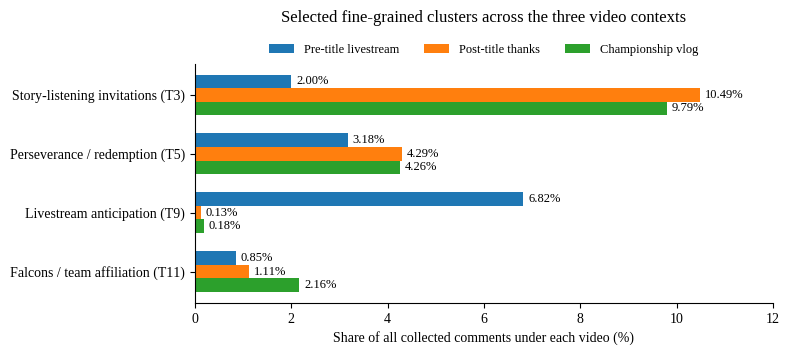

In [20]:
def topic_comparison_figure(count_frame,path=None):
    selected=[3,5,9,11]
    labels=["Story-listening invitations (T3)","Perseverance / redemption (T5)",
            "Livestream anticipation (T9)","Falcons / team affiliation (T11)"]
    matrix=count_frame.pivot(index="topic_15",columns="bvid",values="comment_count").reindex(columns=BVIDS).fillna(0)
    denom=matrix.sum(axis=0)
    percentages=matrix.loc[selected].div(denom,axis=1)*100
    fig,ax=plt.subplots(figsize=(8.0,3.65))
    y=np.arange(len(selected)); width=.23
    for i,bvid in enumerate(BVIDS):
        values=percentages[bvid].to_numpy()
        positions=y+(i-1)*width
        ax.barh(positions,values,height=width,label=SHORT_NAMES[bvid],hatch="")
        for pos,v in zip(positions,values):
            ax.text(v+.10,pos,f"{v:.2f}%",va="center",fontsize=9)
    ax.set_yticks(y,labels);ax.invert_yaxis()
    ax.set_xlim(0,12);ax.set_xlabel("Share of all collected comments under each video (%)")
    ax.set_title("Selected fine-grained clusters across the three video contexts",pad=30)
    ax.legend(loc="upper center",bbox_to_anchor=(.5,1.13),ncol=3,frameon=False,fontsize=9)
    ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout()
    if path: fig.savefig(path,dpi=240,bbox_inches="tight")
    return fig,percentages

fig,topic_percentages=topic_comparison_figure(topic_counts,OUTPUT_DIR/"figures"/"figure2_topic_comparison.png")
display(topic_percentages.round(3))
plt.show();plt.close(fig)
topic_percentages.to_csv(OUTPUT_DIR/"tables"/"selected_topic_percentages_full_corpus.csv",encoding="utf-8-sig")

**Denominator note:** this figure describes the **full 18,877-comment corpus**, unlike Figure 1's seven-day
sentiment sample. It compares video contexts, not equivalent event-time exposure. If the complete local
assignment file is available, the following cell also computes seven-/fourteen-day topic tables without
changing the report's stated full-corpus figure.

In [21]:
if topics_rows is not None:
    for window,col in [("7d","within_7d"),("14d","within_14d")]:
        frame=topics_rows[topics_rows[col]]
        summary=frame.groupby(["bvid","topic_15"]).size().reset_index(name="n")
        summary["within_video_pct"]=100*summary["n"]/summary["bvid"].map(frame.groupby("bvid").size())
        summary.to_csv(OUTPUT_DIR/"tables"/f"topics_{window}_recomputed.csv",index=False,encoding="utf-8-sig")
    print("Additional matched-window topic tables recomputed from the local assignment file.")
else:
    print("Matched-window topic tables NOT calculated: full row-level assignments are needed. No imputation performed.")

row8=audited_topic_sentiment.set_index("topic_15").loc[8]
assert int(row8["negative"])==197 and int(row8.sum())==259
print("T8 high-negative labels:",int(row8["negative"]),"/",int(row8.sum()),
      "=",round(100*row8["negative"]/row8.sum(),2),"% (model output, not an error rate)")

Matched-window topic tables NOT calculated: full row-level assignments are needed. No imputation performed.
T8 high-negative labels: 197 / 259 = 76.06 % (model output, not an error rate)


## 11. Five interpretive themes: completed LLM-assisted reading
The five themes were developed through **actual multi-turn prompt-based dialogue with ChatGPT**,
followed by the researcher's review and explicit approval. This was not a new API classification run.
Inputs included topic tables, transitions, selected high-engagement and diverse comments, and the earlier
comment-level audit. Only selected comments were semantically close-read; computational processing of
all rows must not be confused with human reading of every comment.

The log below reconstructs the analytical decisions from the supplied conversation. The original chat's
precise model build, sampling settings and full token-level transcript were not recorded in the files.
Do not describe this as independent double coding, a controlled inter-model experiment, or validated
five-class prediction. Themes may overlap; there is **no five-theme pie chart or invented frequency table**.

In [22]:
interpretive_themes=pd.DataFrame([
 {"theme_id":"I1","theme":"Championship & Competitive Legacy","definition":"Victory, competitive appraisal and the place assigned to NiKo in esports history.","evidence_topics":"T0 (mixed); relevant excerpts elsewhere","boundary":"A contextual reading, not all T0 comments assigned to one code."},
 {"theme_id":"I2","theme":"Career Redemption & Perseverance","definition":"Earlier disappointment is retold as the path that gives eventual achievement its meaning.","evidence_topics":"T4, T5; relevant unassigned excerpts","boundary":"Can overlap with praise and collective storytelling."},
 {"theme_id":"I3","theme":"Fandom & Emotional Identification","definition":"Support, affection, accompaniment and kinship-like address through which fans position themselves beside the athlete.","evidence_topics":"T6, T7, T10; symbolic material in T1/T14","boundary":"Affectionate address does not by itself establish purchase or behavioural intention."},
 {"theme_id":"I4","theme":"Collective Storytelling & Memes","definition":"Requests to retell the story, ritualised repetition and playful prompts that sustain shared memory.","evidence_topics":"T3, T8, T12, T13; contextual examples","boundary":"Not every question or repeated comment is the same ritual; context matters."},
 {"theme_id":"I5","theme":"Media Engagement & Team Affiliation","definition":"Participation around livestreams/vlogs and expressions of affiliation with the team.","evidence_topics":"T2, T9, T11","boundary":"Two related subdimensions are retained; no claim that they form one homogeneous cluster."}
])
display(interpretive_themes)
interpretive_themes.to_csv(OUTPUT_DIR/"tables"/"five_interpretive_themes.csv",index=False,encoding="utf-8-sig")

interpretation_log=pd.DataFrame([
 {"stage":"Topic-table review","input":"15-topic table and automatic five-topic table","decision":"Treat keyword lists as provisional; inspect comments before interpreting clusters."},
 {"stage":"Assignment and transition audit","input":"Previously uploaded comments_with_topics.csv and 15-to-5 transition table","decision":"Ten fine topics were collapsed into a 10,143-comment mega-topic; reject this as the final five-theme model."},
 {"stage":"Contextual reading","input":"Selected representative, high-engagement and varied comments","decision":"Distinguish narrative content from emojis, repetition and other discourse forms; preserve meaningful unassigned examples."},
 {"stage":"Researcher prompt clarification","input":"User explained that the ongoing prompt-based exchange itself constituted LLM interpretation","decision":"Describe the completed activity as interactive LLM-assisted thematic interpretation, not an unperformed API experiment."},
 {"stage":"Researcher approval","input":"User accepted the five interpretive themes and requested report/Notebook","decision":"Use these five themes to organise findings; retain 15-topic counts as quantitative evidence and report no five-class prevalence."}
])
display(interpretation_log)
interpretation_log.to_csv(OUTPUT_DIR/"tables"/"llm_interpretation_log.csv",index=False,encoding="utf-8-sig")

,theme_id,theme,definition,evidence_topics,boundary
0,I1,Championship & Competitive Legacy,"Victory, competitive appraisal and the place assigned to NiKo in esports history.",T0 (mixed); relevant excerpts elsewhere,"A contextual reading, not all T0 comments assigned to one code."
1,I2,Career Redemption & Perseverance,Earlier disappointment is retold as the path that gives eventual achievement its meaning.,"T4, T5; relevant unassigned excerpts",Can overlap with praise and collective storytelling.
2,I3,Fandom & Emotional Identification,"Support, affection, accompaniment and kinship-like address through which fans position themselve...","T6, T7, T10; symbolic material in T1/T14",Affectionate address does not by itself establish purchase or behavioural intention.
3,I4,Collective Storytelling & Memes,"Requests to retell the story, ritualised repetition and playful prompts that sustain shared memory.","T3, T8, T12, T13; contextual examples",Not every question or repeated comment is the same ritual; context matters.
4,I5,Media Engagement & Team Affiliation,Participation around livestreams/vlogs and expressions of affiliation with the team.,"T2, T9, T11",Two related subdimensions are retained; no claim that they form one homogeneous cluster.


,stage,input,decision
0,Topic-table review,15-topic table and automatic five-topic table,Treat keyword lists as provisional; inspect comments before interpreting clusters.
1,Assignment and transition audit,Previously uploaded comments_with_topics.csv and 15-to-5 transition table,"Ten fine topics were collapsed into a 10,143-comment mega-topic; reject this as the final five-t..."
2,Contextual reading,"Selected representative, high-engagement and varied comments","Distinguish narrative content from emojis, repetition and other discourse forms; preserve meanin..."
3,Researcher prompt clarification,User explained that the ongoing prompt-based exchange itself constituted LLM interpretation,"Describe the completed activity as interactive LLM-assisted thematic interpretation, not an unpe..."
4,Researcher approval,User accepted the five interpretive themes and requested report/Notebook,Use these five themes to organise findings; retain 15-topic counts as quantitative evidence and ...


### Contextual evidence and translated excerpts
Translations below are interpretive glosses, not model labels. Comments are retrieved from the supplied
corpus and displayed without user handles. The exemplar set is purposeful, not a representative validation
sample. The table supports interpretive claims; it does not estimate their prevalence.

In [23]:
evidence_specs=[
 ("I1","本人目前荣誉:","Fans playfully appropriate the athlete's championship as a shared achievement."),
 ("I2","原来最后一把钥匙就藏在故事的开头","The final key to the story was hidden at its beginning."),
 ("I2","夸父终究还是追上了属于他的太阳","Kuafu finally caught up with the sun that belonged to him."),
 ("I3","老爹真性情","Kinship-like address frames support as lasting attachment."),
 ("I4","我坐好了，有人要讲故事吗，文言文现代文外语都可以","I am seated; can someone tell the story? Classical Chinese, modern Chinese or foreign languages are all welcome."),
 ("I4","我已经0.000001秒没听过niko夺冠了的故事了","It has already been 0.000001 seconds since I heard the story of NiKo winning."),
 ("I5","NiKo开播了？！真的假的？！","NiKo is going live?! Really?!"),
 ("I5","We are Falcons","We are Falcons: a shared team slogan.")
]
evidence=[]
for theme,needle,gloss in evidence_specs:
    hits=df[df["comment_text"].str.contains(needle,case=False,regex=False)].copy()
    if hits.empty:
        evidence.append({"theme_id":theme,"text":"NOT FOUND","gloss":gloss})
    else:
        chosen=hits.sort_values("like_count",ascending=False).iloc[0]
        evidence.append({"theme_id":theme,"text":mask_mentions(chosen["comment_text"])[:500],
            "gloss":gloss,"bvid":chosen["bvid"],"source_comment_id":chosen["comment_id"],
            "model_negative_score":chosen["negative_prob"]})
evidence_table=pd.DataFrame(evidence)
assert not evidence_table["text"].eq("NOT FOUND").any()
display(evidence_table.drop(columns=["source_comment_id"]))
evidence_table.to_csv(OUTPUT_DIR/"tables"/"private_evidence_index.csv",index=False,encoding="utf-8-sig")

,theme_id,text,gloss,bvid,model_negative_score
0,I1,本人目前荣誉:\n2024全球总决赛冠军（李相赫赠予）\n2026先锋赛冠军（陈泽彬赠予）\n2026科隆Major冠军（尼古拉科维奇赠予）,Fans playfully appropriate the athlete's championship as a shared achievement.,BV1QSjm6wEBT,0.170827
1,I2,原来最后一把钥匙就藏在故事的开头,The final key to the story was hidden at its beginning.,BV1QSjm6wEBT,0.183280
2,I2,夸父终究还是追上了属于他的太阳,Kuafu finally caught up with the sun that belonged to him.,BV1jsTi67EMC,0.048893
3,I3,老爹真性情[委屈]\n百善孝为先，老爹我孝到你退役那天,Kinship-like address frames support as lasting attachment.,BV1QSjm6wEBT,0.034505
4,I4,我坐好了，有人要讲故事吗，文言文现代文外语都可以[星星眼][星星眼][星星眼],"I am seated; can someone tell the story? Classical Chinese, modern Chinese or foreign languages ...",BV1jsTi67EMC,0.010570
5,I4,我已经0.000001秒没听过niko夺冠了的故事了[星星眼],It has already been 0.000001 seconds since I heard the story of NiKo winning.,BV1u5GR6vELU,0.888093
6,I5,NiKo开播了？！真的假的？！[哦呼],NiKo is going live?! Really?!,BV1u5GR6vELU,0.279835
7,I5,faze up！不好意思走错了，we are falcons！,We are Falcons: a shared team slogan.,BV1QSjm6wEBT,0.224003


## 12. Interpretation, limitations and recommendations

The results support a reading of championship celebration as more than a simple increase in positive
vocabulary. Past disappointments can become the narrative conditions of a meaningful victory. Sitting
down for a story, requesting its repetition and adopting familiar nicknames make belonging visible
through recognisable speech practices. Media requests and team slogans show that this participation
also extends beyond evaluations of match performance.

These are context-sensitive interpretations, not causal estimates. The videos were purposefully chosen;
one pre-title upload and two post-title uploads confound time with content genre and audience selection.
Top-level-only collection misses reply dialogue. Earlier videos attract later retrospective comments.
There is no independent gold standard for sentiment or topic quality. The Chinese classifier also faces
English text, emoji codes, sarcasm and narrative mixtures. BGE's head–tail input and 512-token limits may
lose context. Repetition affects prevalence even after distinct-text fitting. Unassigned HDBSCAN rows are
not necessarily meaningless, and the original top-word representation overemphasised English fragments
and platform symbols. No topic-coherence score, intercoder reliability statistic or superiority claim is
invented to fill these gaps.

For community managers, affectionate irony and ritual repetition deserve contextual attention rather
than automatic treatment as hostility or spam. For researchers, the practical lesson is to retain
source-linked examples, distinguish sentiment from stance, and let computational structure inform—but
not dictate—interpretation.

**AI disclosure:** ChatGPT/Codex assisted programming, debugging, thematic interpretation and prose
preparation. The five themes were developed through dialogue and approved by the researcher. This is
not independent multi-coder validation. The author remains responsible for checking the final submission.

In [24]:
# Final consistency checks and a machine-readable review manifest.
assert len(raw)==18923
assert len(cleaned)==len(df)==18877
assert len(removed)==46
assert int(df["within_7d"].sum())==17319
assert len(topic_table.loc[topic_table.topic_id.ne(-1)])==15
assert int(topic_table.full_comment_count.sum())==18877
assert int(topic_table.loc[topic_table.topic_id.eq(-1),"full_comment_count"].iloc[0])==6155
assert len(interpretive_themes)==5
assert int(audited_topic_sentiment[["positive","negative","uncertain"]].to_numpy().sum())==18877
final_manifest={
    "raw_rows":len(raw),"cleaned_rows":len(df),"first_7d_rows":int(df.within_7d.sum()),
    "sentiment_model":"IDEA-CCNL/Erlangshen-Roberta-110M-Sentiment",
    "embedding_model":"BAAI/bge-base-zh-v1.5",
    "historical_raw_topics":38,"fine_topics":15,"unassigned_rows":6155,
    "interpretive_themes":5,"interpretive_themes_are_comment_labels":False,
    "topic_data_source":topic_data_source,"review_environment":review_environment,
    "sentiment_model_rerun":RUN_SENTIMENT_MODEL,"topic_model_rerun":RUN_TOPIC_MODEL,
    "lexical_tokenizer":LEXICAL_TOKENIZER,"live_collection_executed":False,
    "historical_model_revision":"not recorded in supplied export",
    "input_manifest":DATA_MANIFEST}
(OUTPUT_DIR/"review_manifest.json").write_text(json.dumps(final_manifest,ensure_ascii=False,indent=2),encoding="utf8")
print("All core checks passed. Tables and figures were regenerated from the recorded data.")
print("Report figures:")
print(OUTPUT_DIR/"figures"/"figure1_sentiment_7d.png")
print(OUTPUT_DIR/"figures"/"figure2_topic_comparison.png")

All core checks passed. Tables and figures were regenerated from the recorded data.
Report figures:
/mnt/data/niKo_final_work/review_run/outputs/individual_report/figures/figure1_sentiment_7d.png
/mnt/data/niKo_final_work/review_run/outputs/individual_report/figures/figure2_topic_comparison.png


## References and source notes

- **Primary corpus:** the three BVIDs listed in Section 1; supplied collection and cleaning exports.
  Descriptions are based on titles/metadata and the research brief, not an independent video transcription.
- **IDEA-CCNL.** *Erlangshen-Roberta-110M-Sentiment* [Model card].
  https://huggingface.co/IDEA-CCNL/Erlangshen-Roberta-110M-Sentiment
- **BAAI.** *bge-base-zh-v1.5* [Model card].
  https://huggingface.co/BAAI/bge-base-zh-v1.5
- **Grootendorst, M.** *BERTopic documentation: topic reduction*.
  https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html
- **Course documents:** *NMC5342 Guidelines for Individual Assignment* and *Individual Assignment Template*,
  supplied by the researcher. Advanced-method substitution and AI participation were confirmed by the
  researcher. No TextBlob subjectivity value is fabricated from a binary model's confidence.

### Submission checklist
Fill in your name, NUS email and Student ID in the report; rename both files as requested by the course;
provide a private Notebook/GitHub link and grant the teacher access. Review the raw-text embedding before
any public release. A future rerun of a stochastic pipeline with different dependencies is a new analysis,
not a replacement of the recorded results without reconciliation.